In [1]:
import sys
sys.path.append("..")

from Energy_Production_Data.data_preprocessing import Data_Preprocessing
from Utils import visualize_total_load, visualize_eu_energy, visualize_eu_energy_prices
from Benchmark_Models.Benchmarking import NAS_Benchmarking

from Neural_Architecture_Search.Framework import NAS_Framework


 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.


/home/shaigjr/NAS_GP/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded PyTorch TimesFM, likely because python version is 3.11.15 (main, Mar  3 2026, 09:26:23) [GCC 13.3.0].


### **1.Data Import and Preprocessing**

In [2]:
time_series_preprocessor=Data_Preprocessing()

#import and merge time series for train dataset:
# time_series_preprocessor.merge_train_data()
time_series_preprocessor.merge_train_data_electricity_prices()


#import and merge time series for transfer learn dataset:
time_series_preprocessor.merge_transfer_learn_data()

In [3]:
print('Head of NAS Train Series:')
time_series_preprocessor.eu_energy_prices_frame.head()
# time_series_preprocessor.eu_energy_frame.__len__()
# time_series_preprocessor.eu_energy_prices_frame.__len__()

Head of NAS Train Series:


,Austria Day-ahead Price (EUR/MWh),Belgium Day-ahead Price (EUR/MWh),Bulgaria Day-ahead Price (EUR/MWh),Croatia Day-ahead Price (EUR/MWh),Czech_republic Day-ahead Price (EUR/MWh),Estonia Day-ahead Price (EUR/MWh),Finland Day-ahead Price (EUR/MWh),France Day-ahead Price (EUR/MWh),Germany Day-ahead Price (EUR/MWh),Greece Day-ahead Price (EUR/MWh),Hungary Day-ahead Price (EUR/MWh),Latvia Day-ahead Price (EUR/MWh),Lithuania Day-ahead Price (EUR/MWh),Netherlands Day-ahead Price (EUR/MWh),Poland Day-ahead Price (EUR/MWh),Portugal Day-ahead Price (EUR/MWh),Romania Day-ahead Price (EUR/MWh),Slovakia Day-ahead Price (EUR/MWh),Spain Day-ahead Price (EUR/MWh)
2024-01-10 00:00:00,88.610001,83.000000,89.160004,88.779999,89.040001,87.150002,37.990002,85.300003,89.290001,89.160004,89.190002,87.150002,87.150002,75.540001,90.519997,92.330002,89.160004,89.440002,92.330002
2024-01-10 01:00:00,86.760002,86.760002,86.760002,86.760002,86.760002,84.669998,34.599998,86.760002,86.760002,86.760002,86.760002,84.669998,84.669998,86.760002,87.820000,90.120003,86.760002,86.760002,90.120003
2024-01-10 02:00:00,86.730003,86.730003,86.730003,86.730003,86.730003,84.639999,27.990000,86.730003,86.730003,86.730003,86.730003,84.639999,84.639999,86.730003,88.650002,87.010002,86.730003,86.730003,87.010002
2024-01-10 03:00:00,85.709999,84.059998,85.800003,85.709999,85.889999,84.019997,27.400000,84.750000,86.089996,85.800003,85.809998,84.019997,84.019997,81.220001,88.550003,85.800003,85.800003,85.860001,85.800003
2024-01-10 04:00:00,86.900002,84.180000,87.800003,87.330002,86.949997,84.230003,32.110001,85.000000,86.300003,87.800003,87.779999,84.230003,84.230003,80.480003,90.019997,85.000000,87.800003,88.139999,85.000000


In [4]:
#Create timesteps pandas dataframes and pytorch dataloaders, which will be saved under ../Energy_Production_Data/EU_Time_Series/..
#First create pandas frames:
time_series_preprocessor.create_timestep_frames()

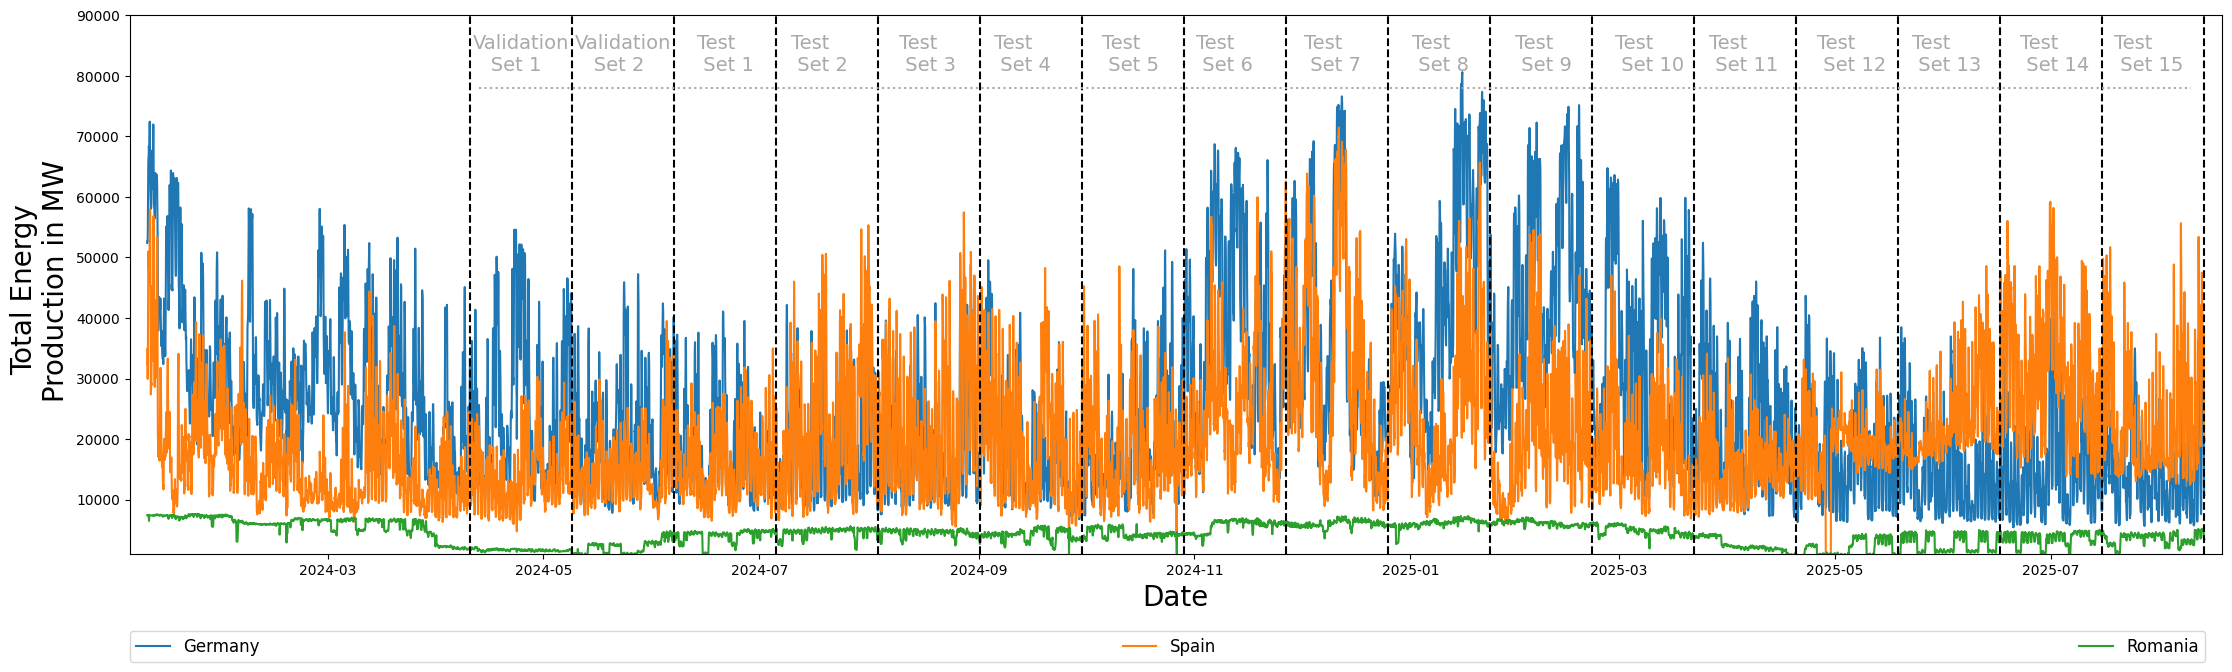

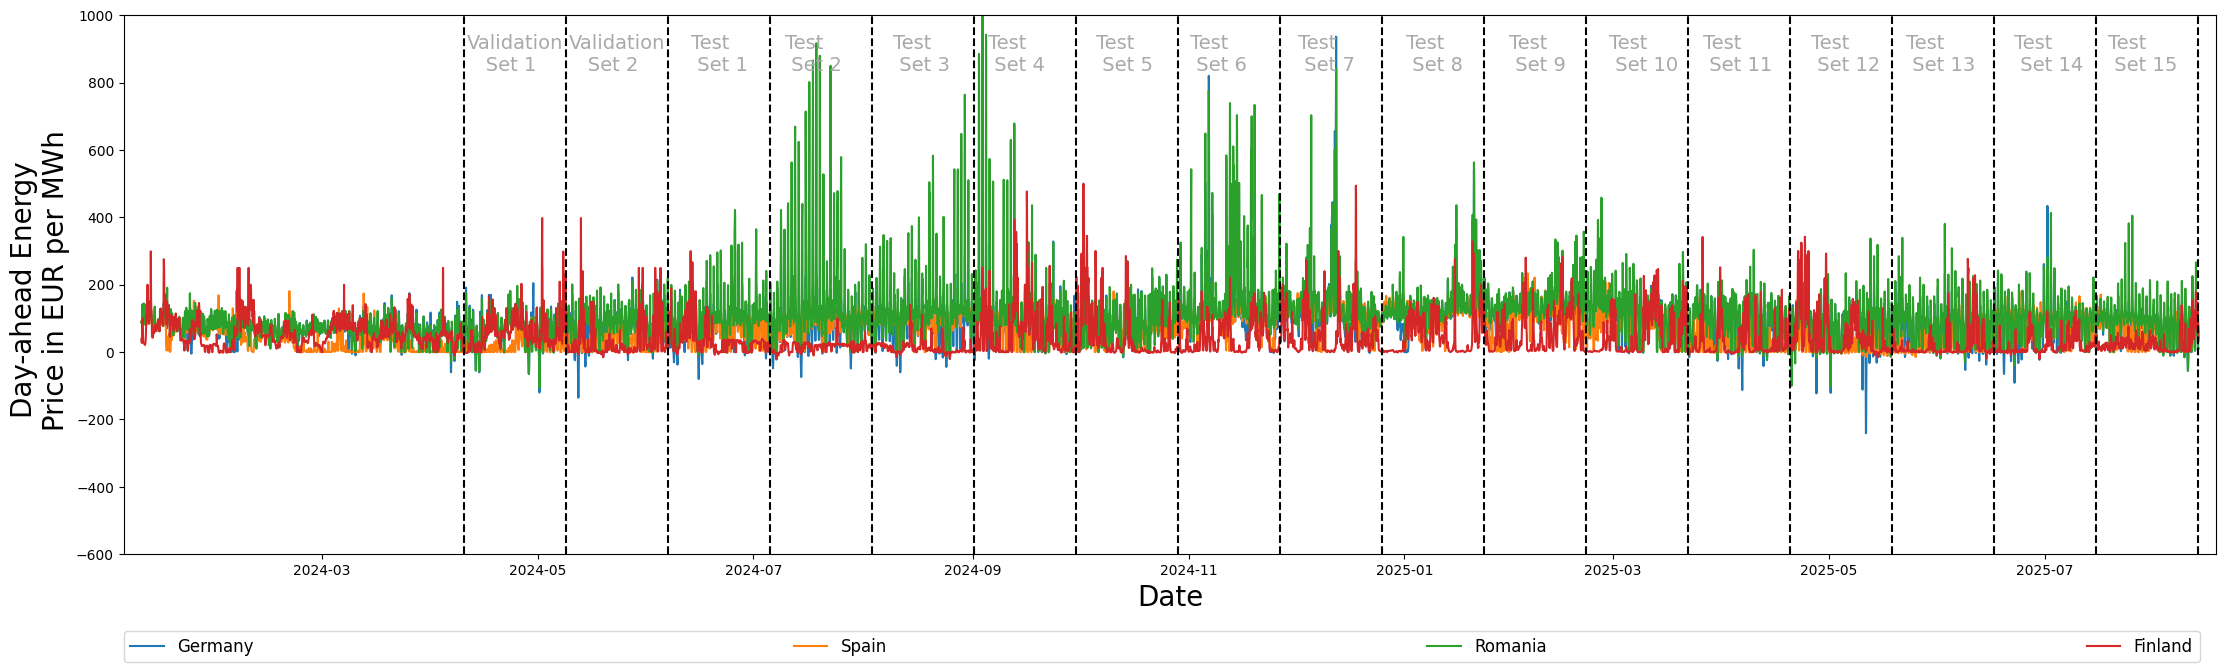

In [5]:
#Afterward, visualize the saved data for the case prediction horizon=192 hours:
visualize_eu_energy(eu_df_path='../Energy_Production_Data/EU_Time_Series/EU_Energy_Time_Series_192_Transfer_Learn.pkl')

visualize_eu_energy_prices(eu_df_path='../Energy_Production_Data/EU_Time_Series/EU_Energy_Prices_Time_Series_192_Train.pkl')

In [6]:
#Once the timesteps dataframes are saved, run the function create_timesteps_dataloaders to create and save dataloaders per prediction horizon in the same folder:
time_series_preprocessor.create_timesteps_dataloaders()

### **2. Time Series Models Training & Testing**

a) Benchmark Models: 
- forecasters requiring dataspecific-training: Basisformer, PatchTST, DLinear, TSMixer, MTSMixer
- pre-trained techniques: TimesFM, Time-MoE, GPT4TS, Sundial
- NAS-related benchmarks: Autogluon-NAS, Dragon-NAS

In [7]:
nas_benchmarking=NAS_Benchmarking()

In [ ]:
#Run baselines, which require dataspecific-trianing: Basisformer, PatchTST, DLinear, TSMixer, MTSMixer
nas_benchmarking.run_multivariate_forecasters()

In [ ]:
#Run baselines, which do not require dataspecific-trianing: TimesFM, Time-MoE, GPT4TS, Sundial
nas_benchmarking.run_pretrained_forecasters()

In [ ]:
#Run NAS baselines: require the highest runtime
#a) Autogluon-NAS:
nas_benchmarking.run_autogluon_nas()

In [ ]:
#b) Dragon-NAS:
nas_benchmarking.run_dragon_nas()

b) NAS

In [9]:
nas_framework=NAS_Framework(embedding_dimension=100,
                            max_number_episodes=1000,timesteps_per_episode=10,
                            ac_units=500,ac_lr=0.0007)

In [10]:
#First we create the search space:
nas_framework.create_search_space(print_components=True)

nr_nodes :  [3, 7] 

node_0_ts_module :  ['Dnonlinear_avgpool1d', 'Dnonlinear_conv1d', 'TSMixer', 'MTSMixer', 'Patching'] 

node_0_kernel_size :  [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37] 

node_0_d_model :  [200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000, 2200, 2400, 2600, 2800, 3000, 3200, 3400, 3600, 3800, 4000, 4200, 4400, 4600, 4800, 5000, 5200, 5400, 5600, 5800, 6000] 

node_0_patch_len :  [8, 12, 16, 20, 24, 28, 32, 36, 40] 

node_0_stride :  [4, 6, 8, 10, 12, 14, 16, 18, 20] 

node_0_dff :  [2, 3, 4, 6] 

node_0_sampling :  [2, 3, 4, 6, 8, 12] 

node_0_dropout :  [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5] 

node_0_activation_1.component :  ['relu', 'elu', 'mish', 'silu', 'sine', 'cosine', 'exp', 'erfcsoftplus', 'leakysinelu', 'leakycosinelu', 'tanh', 'sigmoid', 'gelu', 'linear'] 

node_0_activation_action :  ['multiply', 'add', 'average', None] 

node_0_activation_2.component :  ['relu', 'elu', 'mish', 'silu', 'sine', 'cosine', 'exp', '

In [ ]:
#Run macro WV-GED NAS:
#nas_framework.run_macro_nas(entropy_baseline=False,#Run WV-GED NAS
#                            save_sampling_history=True)